# 01 EDA

In [1]:
%pip install pandas pyarrow
%pip install pandas pyarrow numpy scikit-learn matplotlib seaborn tqdm spacy nltk sentence-transformers

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Import the library

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

### Dataset Overview

In [3]:
URL = "https://storage.googleapis.com/msca-bdp-data-open/news_final_project/news_final_project.parquet"
df = pd.read_parquet(URL, engine="pyarrow")

print("shape:", df.shape)
print("columns:", df.columns.tolist())
df.head(3)

shape: (199989, 5)
columns: ['url', 'date', 'language', 'title', 'text']


,url,date,language,title,text
0,https://blockworks.co/price/bad,2025-06-23,en,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod..."
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,en,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,en,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -..."


### Language Distribution

In [4]:
df['language'].value_counts()

language
en    199989
Name: count, dtype: int64

All articles in the dataset are labeled as English, therefore no language filtering was required.

### Time Distribution

In [5]:
df['date'] = pd.to_datetime(df['date'])
df['date'].describe()

count                 199989
mean     2024-04-15 07:12:01
min      2022-01-01 00:00:00
25%      2023-07-04 00:00:00
50%      2024-02-20 00:00:00
75%      2025-03-19 00:00:00
max      2026-02-10 00:00:00
Name: date, dtype: object

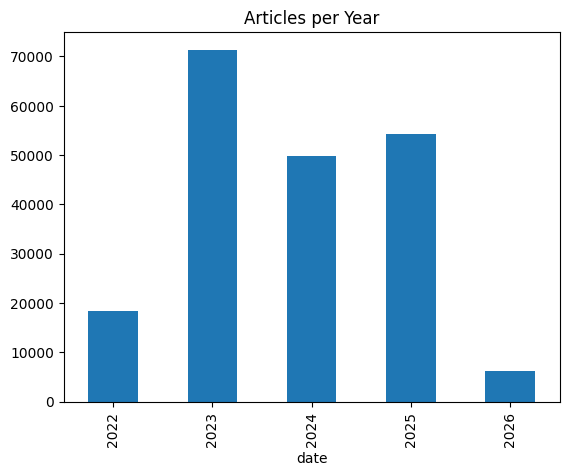

In [6]:
df['date'].dt.year.value_counts().sort_index().plot(kind='bar')
plt.title("Articles per Year")
plt.show()

The dataset spans from 2022 to early 2026, with the majority of articles concentrated between 2023 and 2025.

### Text Length Distribution

In [7]:
df['text_length'] = df['text'].str.len()

df['text_length'].describe()

count    199989.000000
mean       9098.766462
std        7264.733714
min          21.000000
25%        5245.000000
50%        7622.000000
75%       11390.000000
max      580772.000000
Name: text_length, dtype: float64

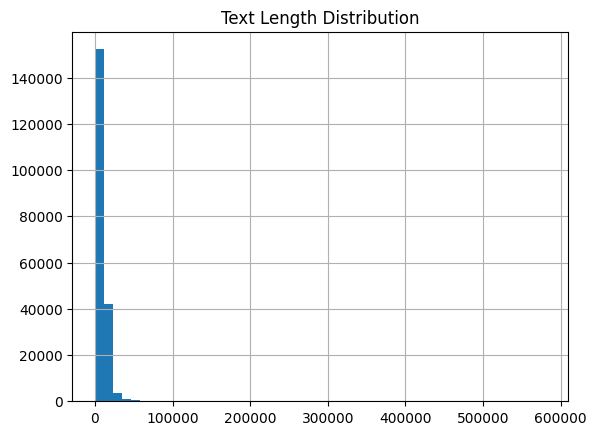

In [8]:
df['text_length'].hist(bins=50)
plt.title("Text Length Distribution")
plt.show()

From the distribution, we can see that most articles contain between 5,000 and 11,000 characters, with a median length of approximately 7,600 characters. A small number of extremely long articles were also observed. Therefore, the dataset may require additional cleaning and preprocessing.

### Missing Values Check

In [9]:
(df.isnull().sum() / len(df)) * 100

url            0.0
date           0.0
language       0.0
title          0.0
text           0.0
text_length    0.0
dtype: float64

No missing values were detected in the dataset across all variables.

### Duplicate Articles Check

In [10]:
duplicate_titles = df['title'].duplicated().sum()

print("Duplicate titles:", duplicate_titles)
print("Duplicate ratio:", duplicate_titles / len(df))

Duplicate titles: 35684
Duplicate ratio: 0.1784298136397502


Approximately 17.8% of articles share duplicate titles, indicating that the dataset likely contains repeated or syndicated news content from different sources.

### Random article inspection

In [11]:
sample = df.sample(30, random_state=42)

for _, row in sample.iterrows():
    print("TITLE:", row['title'])
    print("TEXT:", row['text'][:300])
    print("-"*80)

TITLE: Researchers have developed an AI tool that can closely imitate your handwriting style – Cedar News English
TEXT:   Researchers have developed an AI tool that can closely imitate your handwriting style – Cedar News English
      

Skip to contentThu. Jan 18th, 2024                         

  
HomeBreakingLebanonNewsPoliticsCrimesVideoEntertainmentAR
  
 

News
 
Researchers have developed an AI tool that can c
--------------------------------------------------------------------------------
TITLE: 'Data Science' and 'Machine Learning' at IIT Mandi | CanIndia News
TEXT:  

'Data Science' and 'Machine Learning' at IIT Mandi | CanIndia News

 

Sign in

DIGITAL EDITION
EDITORIAL
NEWS

COMMUNITY
DIASPORA
INDIA
SOUTH ASIA
WORLD


BUSINESS
LIFESTYLE

ART/CULTURE/BOOKS
LIFESTYLE
HEALTH
SCI-TECH


ENTERTAINMENT

BOLLYWOOD
HOLLYWOOD
FILM REVIEWS
TELEVISION
WEB SERIES


SPO
--------------------------------------------------------------------------------
TITLE: Elon Musk threatens to ban wo

To better understand the quality of the dataset, we manually inspected a random sample of 30 articles.

During this inspection, several types of noise introduced by web scraping were identified, including navigation text (e.g., “Skip to content”), section labels (e.g., “CityLife”), and menu fragments (e.g., “All Sections”).

These artifacts do not contribute meaningful information to the article content and will therefore be removed during the data cleaning stage.